# ML Practical - 8
## Soham Admane
### C2-B1-08
#### 08.10.2026

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')


In [ ]:
df = pd.read_csv("ai4i2020.csv")

In [ ]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [ ]:
df.dtypes

,0
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


In [ ]:
df.shape

(10000, 14)

In [ ]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["Type"].unique()

array(['M', 'L', 'H'], dtype=object)

In [ ]:
df["Machine failure"].value_counts()

,count
Machine failure,
0,9661
1,339


In [ ]:
df["Machine failure"].value_counts(normalize=True)*100

,proportion
Machine failure,
0,96.61
1,3.39


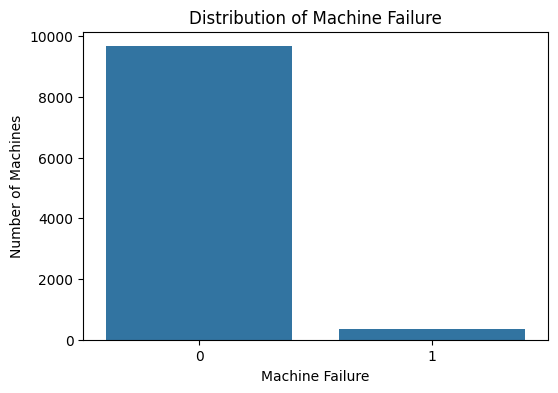

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x="Machine failure", data = df)

plt.title("Distribution of Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Machines")
plt.show()

In [ ]:
numerical_features = ["Air temperature [K]","Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

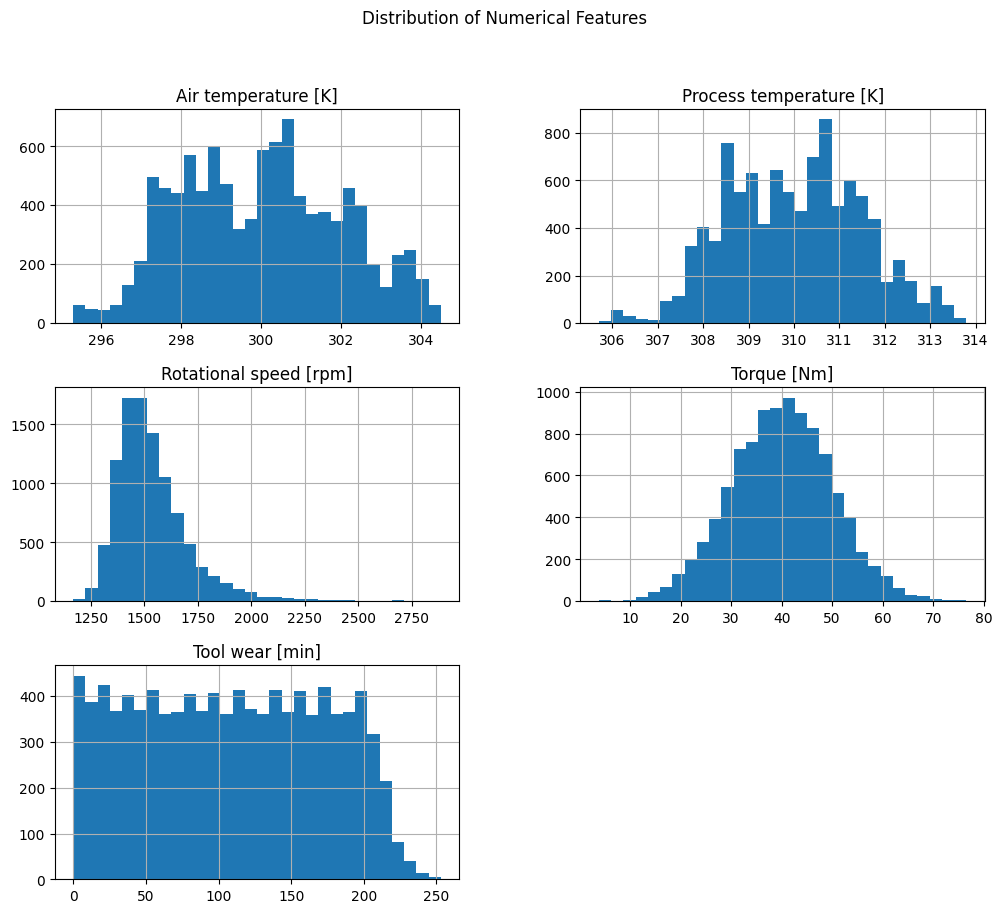

In [ ]:
df[numerical_features].hist(figsize=(12,10), bins = 30)

plt.suptitle("Distribution of Numerical Features")
plt.show()

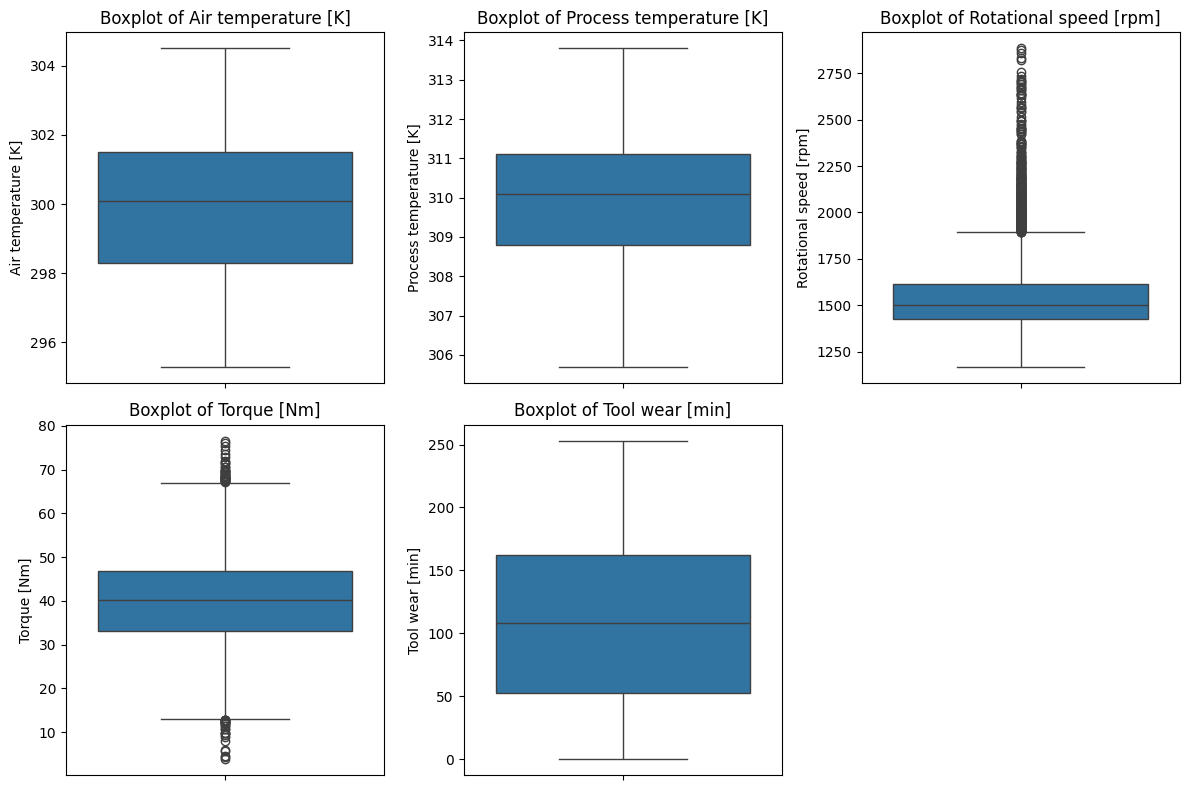

In [ ]:
plt.figure(figsize=(12,8))

for i, column in enumerate(numerical_features,1):
  plt.subplot(2,3,i)
  sns.boxplot(df[column])
  plt.title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

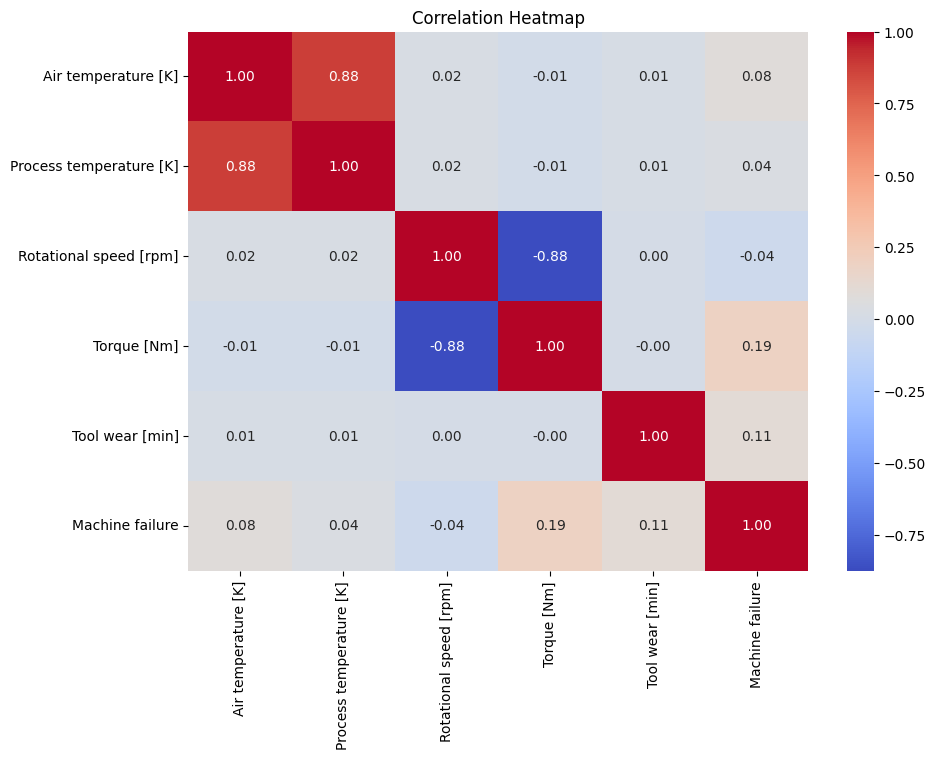

In [ ]:
plt.figure(figsize=(10,7))

correlation = df[numerical_features + ["Machine failure"]].corr()
sns.heatmap(correlation, annot = True, cmap="coolwarm", fmt = ".2f")
plt.title("Correlation Heatmap")
plt.show()

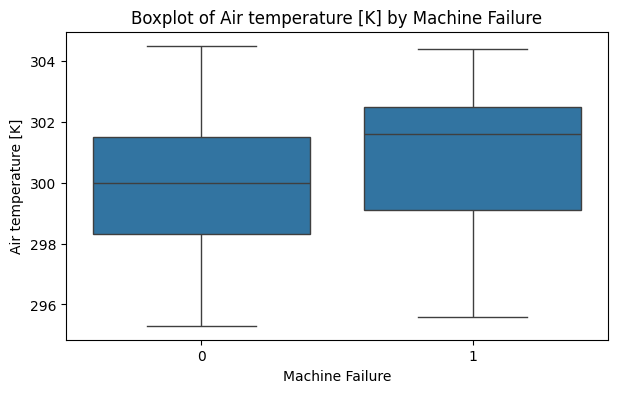

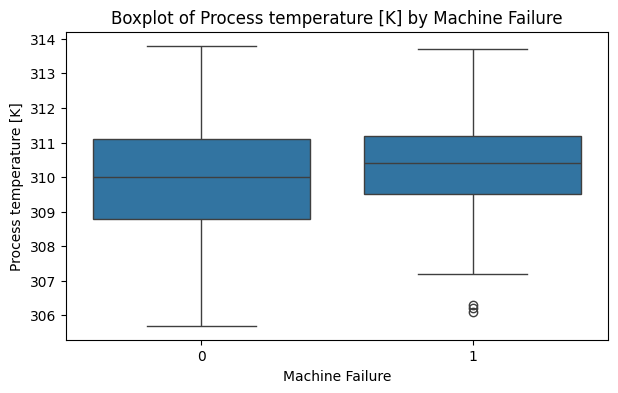

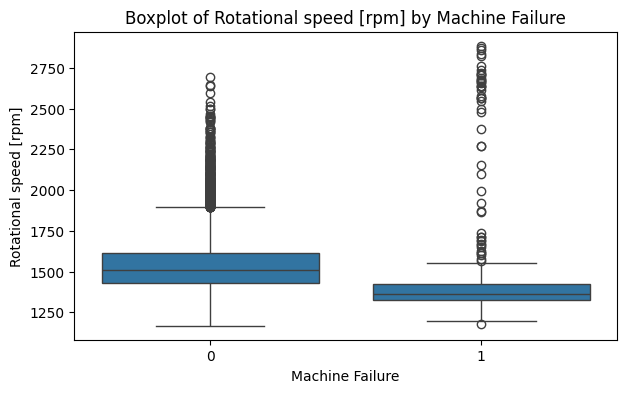

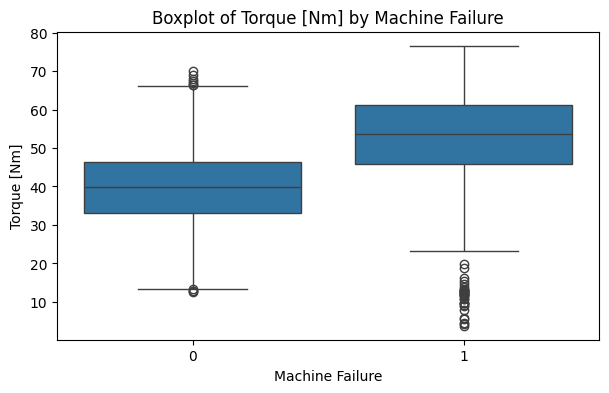

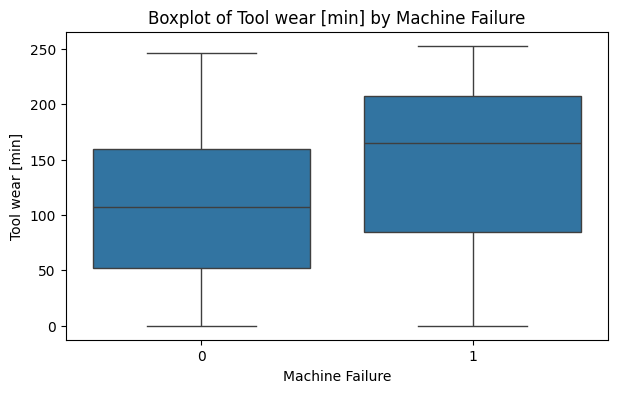

In [ ]:
for column in numerical_features:
  plt.figure(figsize=(7,4))
  sns.boxplot(x="Machine failure", y = column, data = df)
  plt.title(f"Boxplot of {column} by Machine Failure")
  plt.xlabel("Machine Failure")
  plt.ylabel(column)

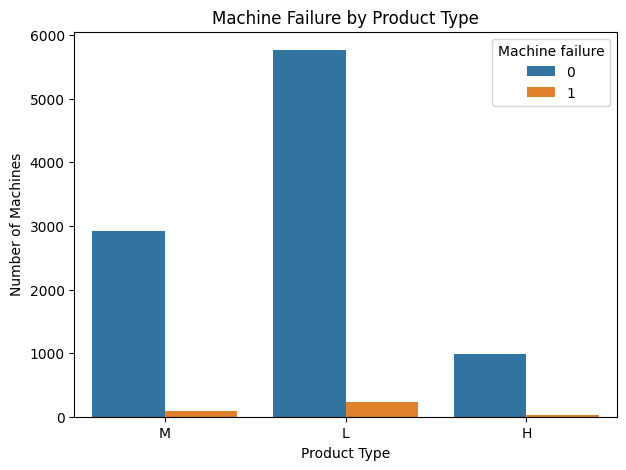

In [ ]:
plt.figure(figsize=(7,5))
sns.countplot(x = "Type", hue = "Machine failure", data = df)
plt.title("Machine Failure by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Number of Machines")

plt.show()

In [ ]:
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

In [ ]:
y = df["Machine failure"]

In [ ]:
print("Input shape: ", X.shape)
print("Output shape: ", y.shape)

Input shape:  (10000, 6)
Output shape:  (10000,)


In [ ]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

print("Training samples: ", X_train.shape[0])
print("Testing samples: ", X_test.shape[0])

Training samples:  8000
Testing samples:  2000


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [ ]:
linear_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="linear"))
    ]
)

linear_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [ ]:
y_pred_linear = linear_svm.predict(X_test)

In [ ]:
accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(y_test, y_pred_linear, zero_division=0)
recall_linear = recall_score(y_test, y_pred_linear, zero_division=0)
f1_linear = f1_score(y_test, y_pred_linear, zero_division=0)

print("Accuracy: ", accuracy_linear)
print("Precision: ", precision_linear)
print("Recall: ", recall_linear)
print("F1 Score: ", f1_linear)

Accuracy:  0.966
Precision:  0.0
Recall:  0.0
F1 Score:  0.0


In [ ]:
print(
    classification_report(y_test, y_pred_linear, target_names=["No Failure", "Failure"]
                          , zero_division=0)
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



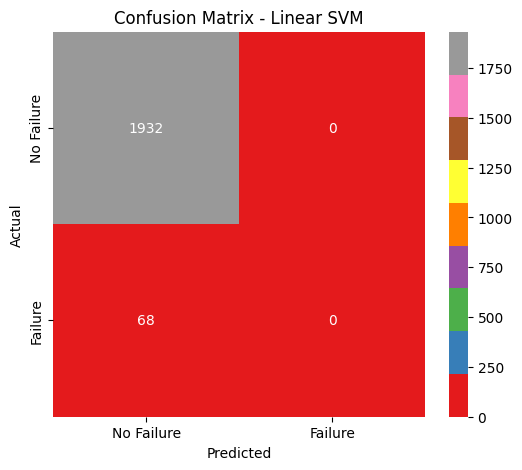

In [ ]:
cm_linear = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize = (6,5))

sns.heatmap(cm_linear, annot = True, fmt = "d", cmap = "Set1",
            xticklabels = ["No Failure", "Failure"],
            yticklabels = ["No Failure", "Failure"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Linear SVM")
plt.show()

In [ ]:
rbf_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="rbf"))
    ]
)

rbf_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [ ]:
y_pred_rbf = rbf_svm.predict(X_test)

In [ ]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf, zero_division=0)
recall_rbf = recall_score(y_test, y_pred_rbf, zero_division=0)
f1_rbf = f1_score(y_test, y_pred_rbf, zero_division=0)

print("Accuracy: ", accuracy_rbf)
print("Precision: ", precision_rbf)
print("Recall: ", recall_rbf)
print("F1 Score: ", f1_rbf)

Accuracy:  0.972
Precision:  0.875
Recall:  0.20588235294117646
F1 Score:  0.3333333333333333


In [ ]:
print(classification_report(y_test, y_pred_rbf, target_names = ["No Failure", "Failure"], zero_division=0))

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



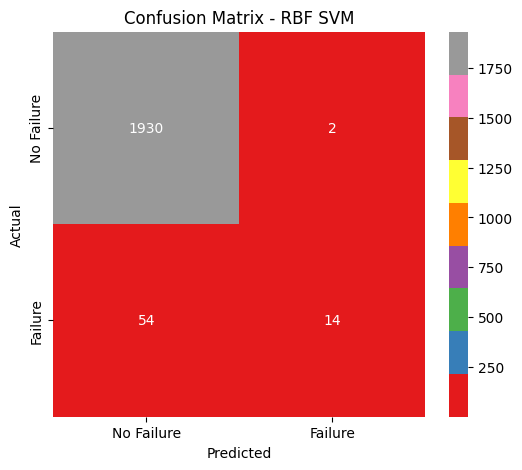

In [ ]:
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize = (6,5))

sns.heatmap(cm_rbf, annot = True, fmt = "d", cmap = "Set1",
            xticklabels = ["No Failure", "Failure"],
            yticklabels = ["No Failure", "Failure"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RBF SVM")
plt.show()

In [ ]:
comparision = pd.DataFrame({
    "Kernel": ["Linear", "RBF"],
    "Accuracy": [accuracy_linear, accuracy_rbf],
    "Precision": [precision_linear, precision_rbf],
    "Recall": [recall_linear, recall_rbf],
    "F1 Score": [f1_linear, f1_rbf]
})

comparision

,Kernel,Accuracy,Precision,Recall,F1 Score
0,Linear,0.966,0.000,0.000000,0.000000
1,RBF,0.972,0.875,0.205882,0.333333


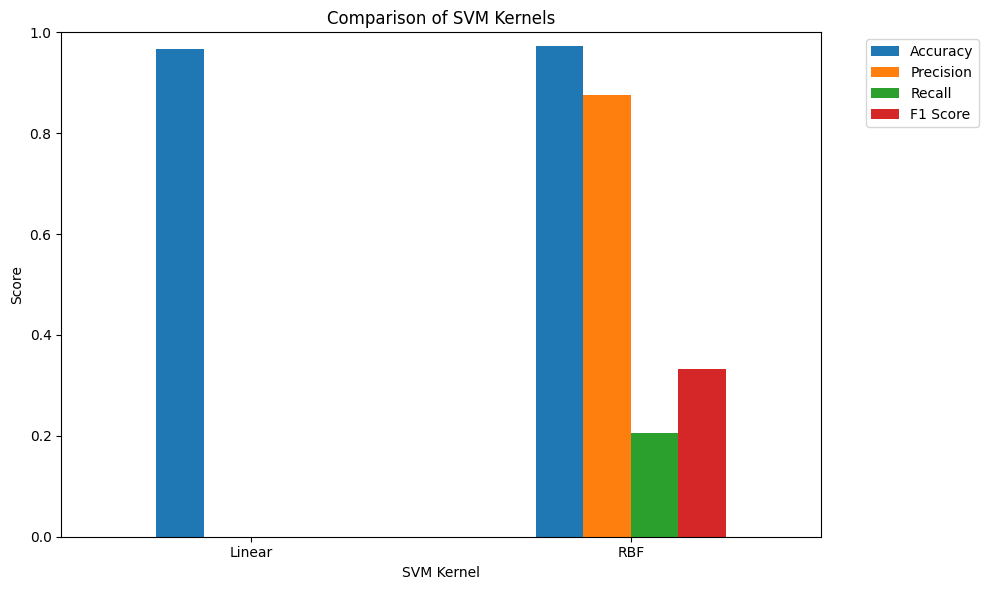

In [ ]:
comparision_plot = comparision.set_index("Kernel")

comparision_plot.plot(kind="bar", figsize=(10,6))

plt.title("Comparison of SVM Kernels")
plt.xlabel("SVM Kernel")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation= 0)
plt.legend(bbox_to_anchor=(1.05,1), loc = "upper left")
plt.tight_layout()
plt.show()

In [ ]:
pipeline = Pipeline(
    steps = [("preprocessor", preprocessor), ("classifier", SVC())]
)

In [ ]:
param_grid = [
    {
        'classifier__kernel': ['linear'],
        'classifier__C': [0.1, 1, 10, 100]
    },
    {
        'classifier__kernel': ['rbf'],
        'classifier__gamma': [0.1, 1, 10, 100],
        'classifier__C': [0.1, 1, 10, 100]
    }
]

In [ ]:
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring="f1", n_jobs=-1, verbose=1)

In [ ]:
grid_search.fit(X_train, y_train)
print("GridSearch CV Completed")
print("Best parameters found:", grid_search.best_params_)
print("Best F1 Score:", grid_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
GridSearch CV Completed
Best parameters found: {'classifier__C': 100, 'classifier__gamma': 0.1, 'classifier__kernel': 'rbf'}
Best F1 Score: 0.6830540778088141


In [ ]:
y_pred_tuned = best_model.predict(X_test)
accuracy_tuned=accuracy_score(y_test,y_pred_tuned)
precision_tuned=precision_score(y_test,y_pred_tuned,zero_division=0)
recall_tuned=recall_score(y_test,y_pred_tuned,zero_division=0)
f1_tuned=f1_score(y_test,y_pred_tuned,zero_division=0)
print('Accuracy:',accuracy_tuned)
print('Precision:',precision_tuned)
print('Recall:',recall_tuned)
print('F1 Score:',f1_tuned)

NameError: name 'best_model' is not defined

In [ ]:
final_comparison=pd.DataFrame({
    'Model':['Linear SVM','RBF SVM','Tuned SVM'],
    'Accuracy':[accuracy_linear,accuracy_rbf,accuracy_tuned],
    'Precision':[precision_linear,precision_rbf,precision_tuned],
    'Recall':[recall_linear,recall_rbf,recall_tuned]})
final_comparison

In [ ]:
final_comparison.set_index('Model').plot(kind='bar',figsize=(8,6))
plt.title('Comparison of Models')
plt.xlabel('Model')
plt.ylabel('score')
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05,1),loc='upper left')
plt.tight_layout()
plt.show()